In [12]:
import torch #for tensor
import torch.nn as nn #module for nn creation
from torch.utils.data import DataLoader #to transfer data in nn by batches
from torchvision import datasets #load existing datasets
from torchvision.transforms import ToTensor #transform photo in tensor
import time
import matplotlib.pyplot as plt

if torch.cuda.is_available(): #try to acess GPU cuda
    print(torch.cuda.get_device_name(0))
    device=torch.device('cuda')
else:
    print("Use CPU")

NVIDIA GeForce RTX 4060 Laptop GPU


In [13]:
#load data
batch_size=512
data_dir='./MNIST' #where to store dataset

train_dataset=datasets.MNIST(data_dir,train=True,download=False,transform=ToTensor()) #MNIST(0-9),take train part,[1,28,28]
test_dataset=datasets.MNIST(data_dir,train=False,transform=ToTensor()) # [32,1,28,28],[32]

train_loader=DataLoader(dataset=train_dataset,batch_size=batch_size,shuffle=True)
test_loader=DataLoader(dataset=test_dataset,batch_size=batch_size,shuffle=True)

for (data, target) in train_loader:
    print('data:', data.size(), 'type:', data.type())
    print('target:', target.size(), 'type:', target.type())
    break

data: torch.Size([512, 1, 28, 28]) type: torch.FloatTensor
target: torch.Size([512]) type: torch.LongTensor


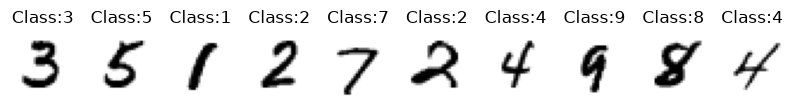

In [14]:
#see images
pltsize=1 #size of the image is 1 inch
plt.figure(figsize=(10*pltsize,pltsize)) #area width and height
for i in range(10):
    plt.subplot(1,10,i+1) #divide area,3rd variable is current part,+1 because matplotlib divide in 1-10
    plt.axis('off') #delete axis
    plt.imshow(data[i,:,:,:].numpy().reshape(28,28),cmap="gray_r") #transform image back to array(28,28),_r make invertion-black numbers
    plt.title("Class:"+str(target[i].item())) #extract from tensor just number not tensor(5)

In [15]:
#Multi Layer Perception
class SimpleMLP(nn.Module): #class inherite from nn.Module
    def __init__(self): #_init_-initialize layers,self-concrete object of the model
        super().__init__()
        self.layers=nn.Sequential( #consecutive layers
            nn.Flatten(), #image to vector [32,784]
            nn.Linear(28*28,20), #20 outputs, 1st hidden layer
            nn.ReLU(),
            nn.Linear(20,10)
        )
    def forward(self,x): #defines how network performs a forward pass
        return self.layers(x)
    #backward automatically generated

model=SimpleMLP().to(device)
print(model)

criterion=nn.CrossEntropyLoss() #tipycally used for a multi class classiification
optimizer=torch.optim.Adam(model.parameters())

SimpleMLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=20, bias=True)
    (2): ReLU()
    (3): Linear(in_features=20, out_features=10, bias=True)
  )
)


In [16]:
#Train
def train(data_loader,model,criterion,optimizer):
    model.train() #Use if have dropout or normalization

    num_batches=len(data_loader) #60k/32=1875
    num_items=len(data_loader.dataset) #60k

    total_loss=0 #sum each batch
    total_correct=0 #sum each batch

    for data,target in data_loader:
        data=data.to(device)
        target=target.to(device)
        
        optimizer.zero_grad() #clean gradients
        output=model(data) #put 32i

        loss=criterion(output,target) #count and averaging error
        total_loss+=loss.item() #to add a number
        total_correct+=correct(output,target)

        loss.backward() #count gradients
        optimizer.step()

    train_loss=total_loss/num_batches
    accuracy=total_correct/num_items
    print(f"Avg loss{train_loss:7f},accuracy:{accuracy:.2%}")

def correct(output,target):
    predicted_digits=output.argmax(1)
    correct_ones=(predicted_digits==target).type(torch.float)
    return correct_ones.sum().item()

#Evaluation
def test(test_loader,model,criterion):
    model.eval() #Use if have dropout or normalization

    num_batches=len(test_loader) #313
    num_items=len(test_loader.dataset) #10k
    test_loss=0
    total_correct=0

    with torch.no_grad(): #no need to compute and save gradient
        for data,target in test_loader:
            data=data.to(device)
            target=target.to(device)

            output=model(data)

            loss=criterion(output,target)
            test_loss+=loss.item()
            total_correct+=correct(output,target)

        test_loss=test_loss/num_batches
        accuracy=total_correct/num_items

        print(f"Accuracy:{100*accuracy:>0.1f}%,avg loss:{test_loss:>7f}")


In [17]:
#Training
epochs=15
for epoch in range(epochs):
    print(f"Epoch:{epoch+1}")
    
    start_time = time.time() #Time of the start
    
    train(train_loader,model,criterion,optimizer)
    
    end_time = time.time()  #Time of the end
    epoch_duration = end_time - start_time  #Count difference
    print(f"Epoch {epoch+1} finished in {epoch_duration:.2f} seconds\n")

Epoch:1
Avg loss1.202273,accuracy:70.24%
Epoch 1 finished in 10.18 seconds

Epoch:2
Avg loss0.450942,accuracy:88.32%
Epoch 2 finished in 9.66 seconds

Epoch:3
Avg loss0.346081,accuracy:90.54%
Epoch 3 finished in 9.39 seconds

Epoch:4
Avg loss0.306756,accuracy:91.35%
Epoch 4 finished in 10.15 seconds

Epoch:5
Avg loss0.285119,accuracy:91.94%
Epoch 5 finished in 9.50 seconds

Epoch:6
Avg loss0.270835,accuracy:92.32%
Epoch 6 finished in 9.60 seconds

Epoch:7
Avg loss0.259522,accuracy:92.72%
Epoch 7 finished in 10.14 seconds

Epoch:8
Avg loss0.246368,accuracy:93.02%
Epoch 8 finished in 9.62 seconds

Epoch:9
Avg loss0.235754,accuracy:93.37%
Epoch 9 finished in 10.02 seconds

Epoch:10
Avg loss0.227770,accuracy:93.57%
Epoch 10 finished in 10.50 seconds

Epoch:11
Avg loss0.217764,accuracy:93.89%
Epoch 11 finished in 9.39 seconds

Epoch:12
Avg loss0.211133,accuracy:94.12%
Epoch 12 finished in 9.76 seconds

Epoch:13
Avg loss0.203343,accuracy:94.34%
Epoch 13 finished in 9.53 seconds

Epoch:14
Avg

In [18]:
#Test
print("Test")
test(test_loader,model,criterion)

Test
Accuracy:94.2%,avg loss:0.197134
